# Eksperimen & Modeling K-Nearest Neighbors (KNN) — Deteksi Situs Web Phishing
**PIC:** Irfan (Anggota 4 — Deployment Engineer)  
**Dataset:** `dataset/output/` (4.679 train, 1.170 test, 30 fitur indikator keamanan)  
**Target:** `Result` (`0` = Legitimate / Aman, `1` = Phishing / Berbahaya)

Tahapan dalam notebook ini:
1. Memuat dataset bersama (`X_train`, `X_test`, `y_train`, `y_test`) dan `scaler.pkl`.
2. Eksperimen pencarian nilai `k` terbaik (`k = 3, 5, 7, 9, 11, 15, 21`).
3. Evaluasi model terbaik pada data uji (*Accuracy, Precision, Recall Phishing, F1-Score, ROC-AUC, Confusion Matrix*).
4. Menyimpan model terbaik ke `models/knn_model.pkl` dan ringkasan metrik ke `evaluation/knn_metrics.json`.

In [1]:
import json
import time
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    accuracy_score,
    classification_report,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.neighbors import KNeighborsClassifier

DATA_DIR = Path("../dataset/output")
MODEL_DIR = Path("../models")
EVAL_DIR = Path("../evaluation")
MODEL_DIR.mkdir(exist_ok=True)
EVAL_DIR.mkdir(exist_ok=True)

## 1. Memuat Dataset & Standardisasi Fitur
Algoritma KNN berbasis jarak Euclidean, sehingga fitur ditransformasikan menggunakan `scaler.pkl` (fit hanya pada `X_train`).

In [2]:
X_train = pd.read_csv(DATA_DIR / "X_train.csv")
X_test = pd.read_csv(DATA_DIR / "X_test.csv")
y_train = pd.read_csv(DATA_DIR / "y_train.csv").squeeze()
y_test = pd.read_csv(DATA_DIR / "y_test.csv").squeeze()

scaler = joblib.load(DATA_DIR / "scaler.pkl")
X_train_scaled = scaler.transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"X_train: {X_train_scaled.shape} | X_test: {X_test_scaled.shape}")
print("Proporsi y_test (0=Legitimate, 1=Phishing):", y_test.value_counts().to_dict())

X_train: (4679, 30) | X_test: (1170, 30)
Proporsi y_test (0=Legitimate, 1=Phishing): {1: 604, 0: 566}


## 2. Eksperimen Pencarian Nilai `k` Terbaik
Menguji `k = 3, 5, 7, 9, 11, 15, 21` dan memantau *Accuracy*, *Precision*, *Recall (Phishing)*, *F1-Score (Phishing)*, dan *ROC-AUC*.

In [3]:
k_values = [3, 5, 7, 9, 11, 15, 21]
results = []

for k in k_values:
    t0 = time.perf_counter()
    model = KNeighborsClassifier(n_neighbors=k, n_jobs=-1)
    model.fit(X_train_scaled, y_train)
    train_time = time.perf_counter() - t0

    t1 = time.perf_counter()
    y_pred = model.predict(X_test_scaled)
    y_proba = model.predict_proba(X_test_scaled)[:, 1]
    pred_time = time.perf_counter() - t1

    results.append({
        "k": k,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision_Phishing": precision_score(y_test, y_pred, pos_label=1),
        "Recall_Phishing": recall_score(y_test, y_pred, pos_label=1),
        "F1_Phishing": f1_score(y_test, y_pred, pos_label=1),
        "ROC_AUC": roc_auc_score(y_test, y_proba),
        "Train_Time_s": round(train_time, 4),
        "Pred_Time_s": round(pred_time, 4),
    })

results_df = pd.DataFrame(results)
results_df.round(4)

,k,Accuracy,Precision_Phishing,Recall_Phishing,F1_Phishing,ROC_AUC,Train_Time_s,Pred_Time_s
0,3,0.9085,0.9121,0.9106,0.9114,0.9580,0.0056,2.0175
1,5,0.9162,0.9161,0.9222,0.9191,0.9701,0.0017,0.0259
2,7,0.9179,0.9137,0.9288,0.9212,0.9738,0.0011,0.0285
3,9,0.9154,0.9146,0.9222,0.9184,0.9738,0.0016,0.0293
4,11,0.9214,0.9183,0.9305,0.9243,0.9760,0.0016,0.0296
5,15,0.9205,0.9168,0.9305,0.9236,0.9754,0.0016,0.0347
6,21,0.9120,0.9113,0.9189,0.9151,0.9742,0.0016,0.0384


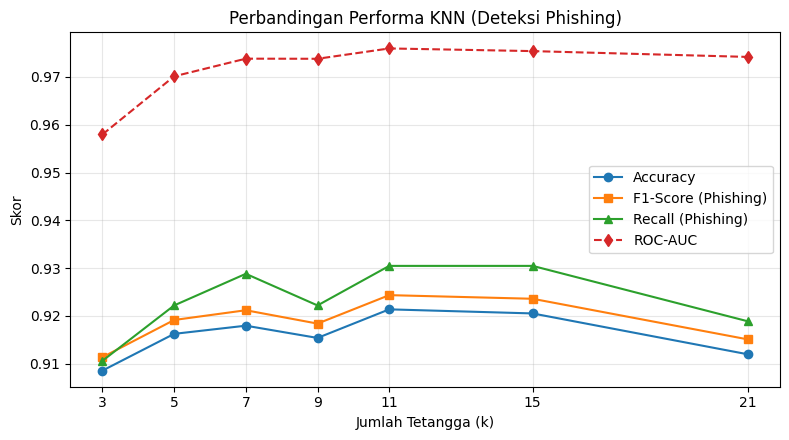

In [4]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(results_df["k"], results_df["Accuracy"], marker="o", label="Accuracy")
ax.plot(results_df["k"], results_df["F1_Phishing"], marker="s", label="F1-Score (Phishing)")
ax.plot(results_df["k"], results_df["Recall_Phishing"], marker="^", label="Recall (Phishing)")
ax.plot(results_df["k"], results_df["ROC_AUC"], marker="d", linestyle="--", label="ROC-AUC")
ax.set_title("Perbandingan Performa KNN (Deteksi Phishing)")
ax.set_xlabel("Jumlah Tetangga (k)")
ax.set_ylabel("Skor")
ax.set_xticks(k_values)
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

## 3. Pelatihan & Evaluasi Model Terbaik
Memilih nilai `k` dengan kombinasi *F1-Score (Phishing)* dan *ROC-AUC* tertinggi, lalu menampilkan `classification_report`, *Confusion Matrix*, dan kurva *ROC-AUC*.

In [5]:
best_row = results_df.sort_values(by=["F1_Phishing", "ROC_AUC"], ascending=False).iloc[0]
best_k = int(best_row["k"])
print(f"Nilai k terbaik terpilih: k = {best_k}")

t0 = time.perf_counter()
best_knn = KNeighborsClassifier(n_neighbors=best_k, n_jobs=-1)
best_knn.fit(X_train_scaled, y_train)
best_train_time = time.perf_counter() - t0

y_pred_best = best_knn.predict(X_test_scaled)
y_proba_best = best_knn.predict_proba(X_test_scaled)[:, 1]

print("\nClassification Report (0 = Legitimate, 1 = Phishing):")
print(classification_report(y_test, y_pred_best, target_names=["Legitimate (0)", "Phishing (1)"], digits=4))

Nilai k terbaik terpilih: k = 11

Classification Report (0 = Legitimate, 1 = Phishing):
                precision    recall  f1-score   support

Legitimate (0)     0.9247    0.9117    0.9181       566
  Phishing (1)     0.9183    0.9305    0.9243       604

      accuracy                         0.9214      1170
     macro avg     0.9215    0.9211    0.9212      1170
  weighted avg     0.9214    0.9214    0.9213      1170



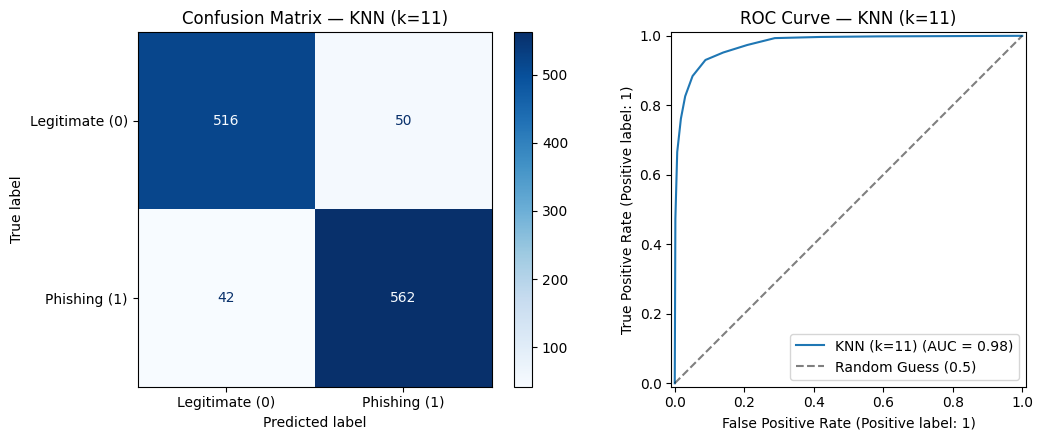

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_best,
    display_labels=["Legitimate (0)", "Phishing (1)"],
    cmap="Blues",
    ax=axes[0],
)
axes[0].set_title(f"Confusion Matrix — KNN (k={best_k})")

RocCurveDisplay.from_predictions(
    y_test,
    y_proba_best,
    name=f"KNN (k={best_k})",
    ax=axes[1],
)
axes[1].plot([0, 1], [0, 1], "k--", alpha=0.5, label="Random Guess (0.5)")
axes[1].set_title(f"ROC Curve — KNN (k={best_k})")
axes[1].legend()

plt.tight_layout()
plt.show()

## 4. Simpan Model & Metrik Evaluasi
Menyimpan model terbaik ke `models/knn_model.pkl` dan metrik ringkasan ke `evaluation/knn_metrics.json`.

In [7]:
model_path = MODEL_DIR / "knn_model.pkl"
joblib.dump(best_knn, model_path)

metrics_summary = {
    "Algoritma": f"K-Nearest Neighbors (k={best_k})",
    "PIC": "Irfan",
    "best_params": {"n_neighbors": best_k, "metric": "minkowski", "p": 2},
    "Accuracy": round(float(accuracy_score(y_test, y_pred_best)), 4),
    "Precision (Phishing)": round(float(precision_score(y_test, y_pred_best, pos_label=1)), 4),
    "Recall (Phishing)": round(float(recall_score(y_test, y_pred_best, pos_label=1)), 4),
    "F1-Score (Phishing)": round(float(f1_score(y_test, y_pred_best, pos_label=1)), 4),
    "ROC-AUC": round(float(roc_auc_score(y_test, y_proba_best)), 4),
    "Train Time (s)": round(float(best_train_time), 4),
}

metrics_path = EVAL_DIR / "knn_metrics.json"
with open(metrics_path, "w", encoding="utf-8") as f:
    json.dump(metrics_summary, f, indent=2)

print("Model tersimpan di:", model_path.resolve())
print("Metrik tersimpan di:", metrics_path.resolve())
print(json.dumps(metrics_summary, indent=2))

Model tersimpan di: C:\Users\irfan\Kuliah\INFORMATIKA UNS\Semester 5\datmin\Team-Based Project\Kelompok-4_Team-Based-Project_Data-Mining\models\knn_model.pkl
Metrik tersimpan di: C:\Users\irfan\Kuliah\INFORMATIKA UNS\Semester 5\datmin\Team-Based Project\Kelompok-4_Team-Based-Project_Data-Mining\evaluation\knn_metrics.json
{
  "Algoritma": "K-Nearest Neighbors (k=11)",
  "PIC": "Irfan",
  "best_params": {
    "n_neighbors": 11,
    "metric": "minkowski",
    "p": 2
  },
  "Accuracy": 0.9214,
  "Precision (Phishing)": 0.9183,
  "Recall (Phishing)": 0.9305,
  "F1-Score (Phishing)": 0.9243,
  "ROC-AUC": 0.976,
  "Train Time (s)": 0.0015
}
